# Initialisation des Bibliothèque

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset_reussite_etudiants_300.csv')
df.head()

,heures_etude_semaine,taux_presence_pct,exercices_realises,note_controle_continu,temps_plateforme_h_semaine,devoirs_rendus,participation_classe_10,reussite
0,4.8,78.6,24,16.9,11.8,4,9.5,1
1,9.0,64.5,17,6.3,6.3,8,6.3,0
2,1.0,92.1,23,11.6,7.1,9,8.3,0
3,13.6,98.8,6,14.1,5.1,9,5.9,1
4,10.6,78.8,16,13.4,9.4,6,6.6,0


# EDA

- Exploration du dataset avec:
 
   - Shape pour voir la taille du dataset
   - Dtypes pour voir les types de nos variables
   - ET isnull() pour connaitre le nombre de valeurs manquante  

In [12]:
df.shape

(300, 8)

In [13]:
df.dtypes

heures_etude_semaine          float64
taux_presence_pct             float64
exercices_realises              int64
note_controle_continu         float64
temps_plateforme_h_semaine    float64
devoirs_rendus                  int64
participation_classe_10       float64
reussite                        int64
dtype: object

In [6]:
missing= df.isna().sum()
missing =  missing[missing > 0]

In [7]:
#traitement des valeurs manquante
df['taux_presence_pct'] = df['taux_presence_pct'].fillna(df['taux_presence_pct'].median())
df['note_controle_continu'] = df['note_controle_continu'].fillna(df['note_controle_continu'].median())
df['temps_plateforme_h_semaine'] = df['temps_plateforme_h_semaine'].fillna(df['temps_plateforme_h_semaine'].median())

In [8]:
stat= df.describe()
stat

,heures_etude_semaine,taux_presence_pct,exercices_realises,note_controle_continu,temps_plateforme_h_semaine,devoirs_rendus,participation_classe_10,reussite
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,8.391333,77.637000,18.220000,12.131333,5.314667,6.796667,6.412333,0.543333
std,4.094240,12.810431,6.780722,2.907634,2.403854,2.326664,1.979514,0.498951
min,1.000000,40.000000,2.000000,5.000000,0.500000,1.000000,1.000000,0.000000
25%,5.300000,68.450000,14.000000,10.200000,3.600000,5.000000,4.900000,0.000000
50%,8.400000,78.300000,18.000000,12.200000,5.200000,7.000000,6.300000,1.000000
75%,11.000000,87.200000,23.000000,14.100000,6.850000,9.000000,8.000000,1.000000
max,20.000000,100.000000,30.000000,20.000000,13.800000,10.000000,10.000000,1.000000


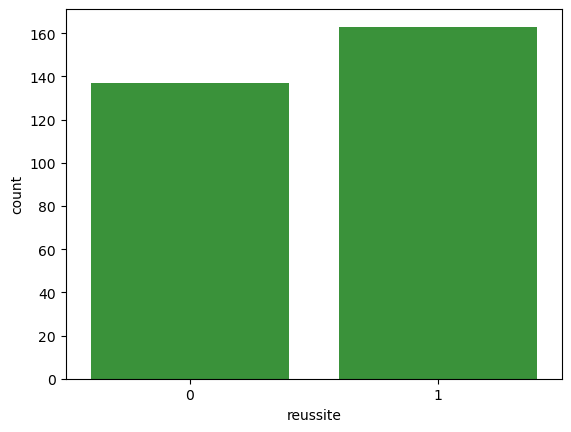

In [27]:
sns.countplot(x='reussite', data= df)
plt.show()

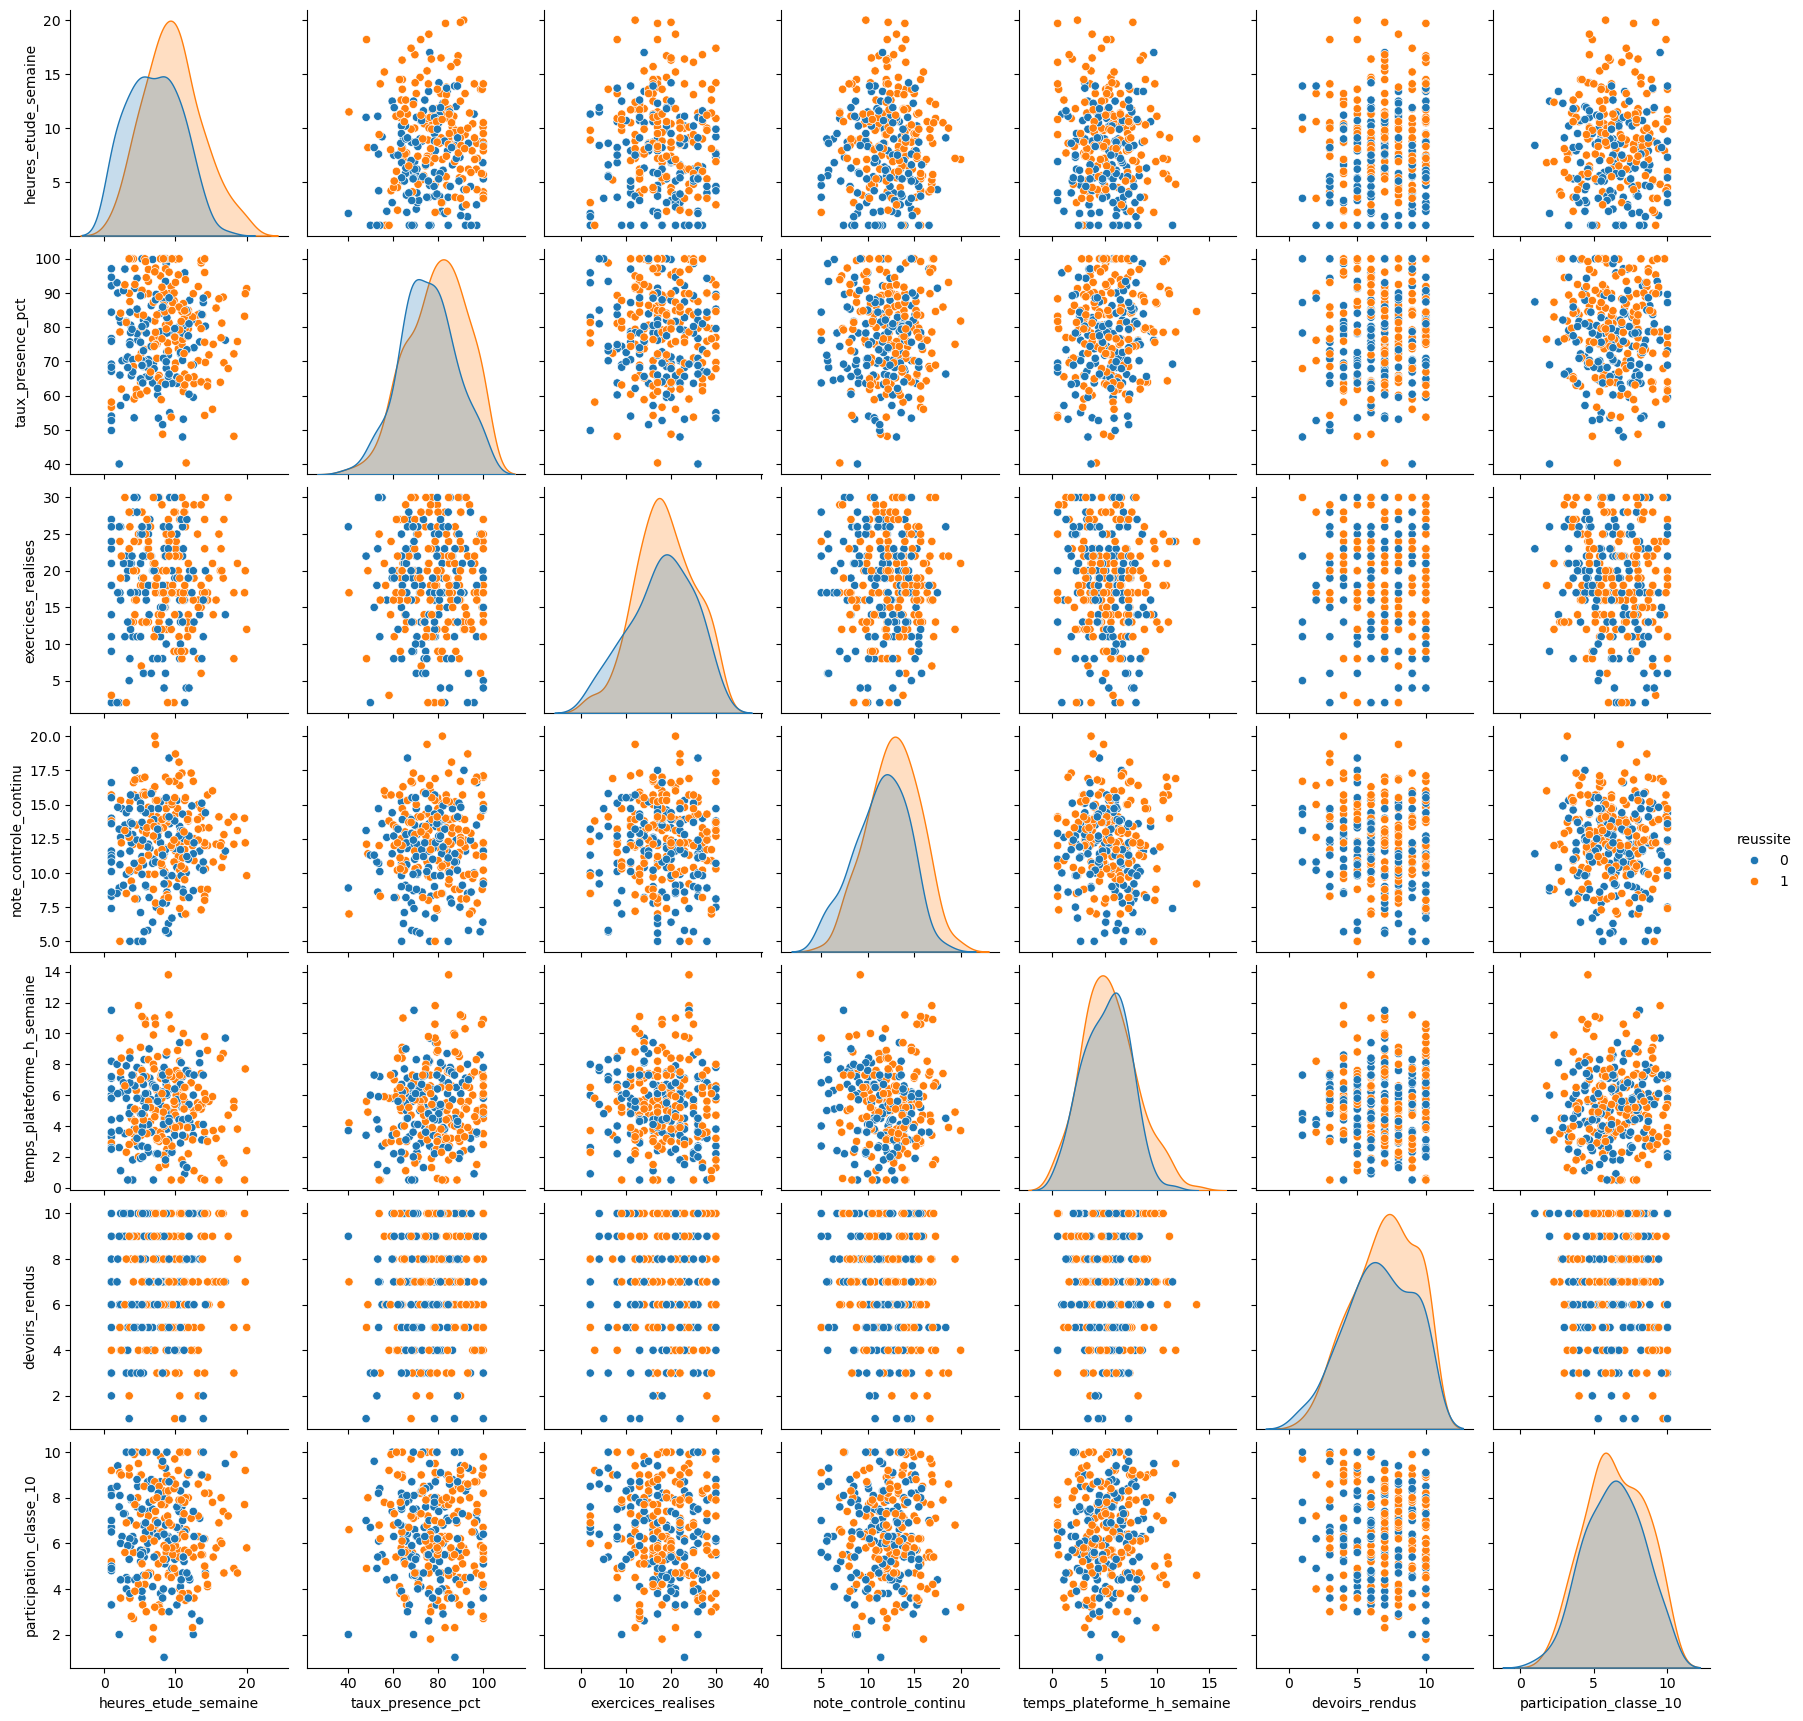

In [32]:
#création de graphe pour le dataset
sns.pairplot(df, hue='reussite')
plt.show()

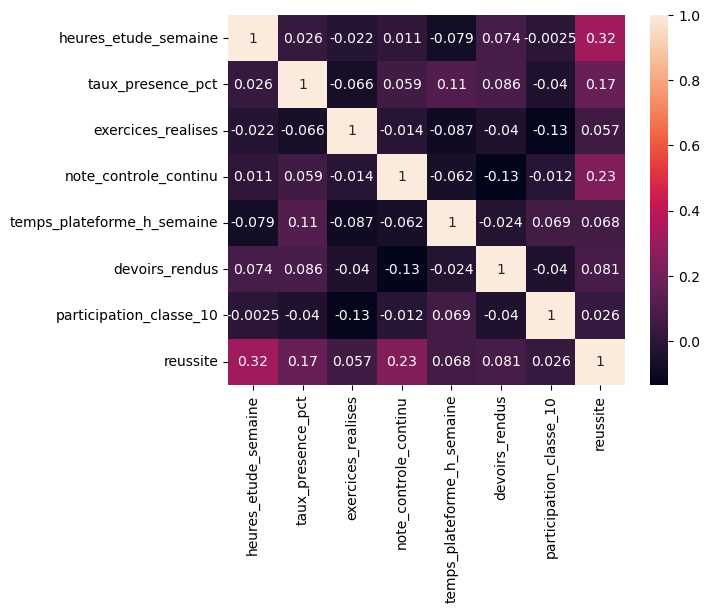

In [34]:
sns.heatmap(df.corr(),annot= True)
plt.show()

In [24]:
#entrainement du modèle
X= df.drop('reussite', axis=1)
y= df['reussite']

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, confusion_matrix, f1_score, ConfusionMatrixDisplay
X_train,X_test,y_train,y_test= train_test_split(X,y, test_size=0.2, random_state=15)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_reg= LogisticRegression(  )
model_reg.fit(X_train_scaled, y_train)
y_pred = model_reg.predict(X_test_scaled)
recall_score(y_test, y_pred)
print(confusion_matrix(y_test, y_pred))


[[14 13]
 [ 7 26]]


{'class_weight': {0: 1, 1: 5}, 'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 200}
F1 (validation croisée) : 0.7315886482798247
[[ 7 20]
 [ 1 32]]
              precision    recall  f1-score   support

      Normal       0.88      0.26      0.40        27
      Fraude       0.62      0.97      0.75        33

    accuracy                           0.65        60
   macro avg       0.75      0.61      0.58        60
weighted avg       0.73      0.65      0.59        60



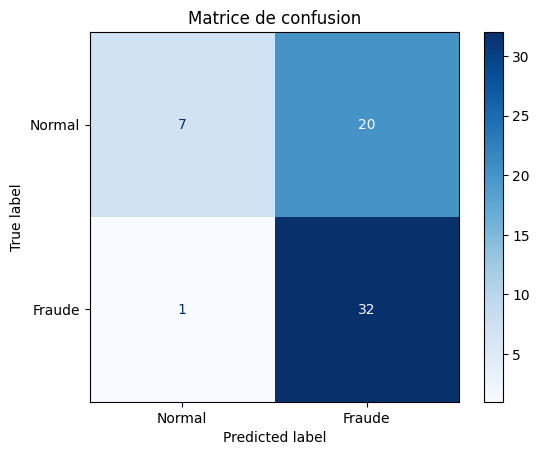

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report,  f1_score

m_rf = RandomForestClassifier()
m_rf.fit(X_train, y_train)
y_pred_rf = m_rf.predict(X_test)

print(confusion_matrix(y_test, y_pred_rf))

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["Normal", "Fraude"],
    cmap="Blues"
)

plt.title("Matrice de confusion")
plt.show()